# Noria · 05 — Calibration, risk classes, explainability and checks

Session 5, run as pre-registered in `docs/experiments.md` (commit "Pre-register E14 and session 5 protocol").

- **E8** calibration (calibrators fitted on out-of-fold **train** predictions) · **E14** risk classes
- **E4** region features · **E5** clients without a credit-bureau record · **E6** target population · **E9** fairness audit
- **SHAP** explanations of the final bank-without-history and client models

Models: the final session 4 models (52, 65 and 7 features, tuned parameters). All metrics on the **validation** set.
**The test set stays locked.** Logic in `src/calibration.py`, `src/risk.py`, `src/analysis.py`, `src/explain.py`, `src/experiments_s5.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.calibration import calibration_curve

from src import config, data, analysis, explain, risk, experiments_s5 as s5
from src import evaluate as ev

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / name, dpi=120, bbox_inches="tight")
    print(f"Figure saved: reports/figures/{name}")

def ci(d, key="auc_diff"):
    return f"{d[key]:+.4f} [{d['ci_low']:+.4f}, {d['ci_high']:+.4f}]"

In [2]:
try:
    data.load_split("test")
except data.TestSetLockedError as error:
    print("As expected:", error)
train, val = data.load_train_val()
y_val = val[config.TARGET].to_numpy()
models = s5.final_models(train, val)
print({name: f"{len(m['features'])} features, {m['pipeline'].named_steps['model'].n_estimators} trees" for name, m in models.items()})

As expected: The test set is locked until the final evaluation. Use load_split('test', final=True) only for the final results.


{'bank_no_history': '52 features, 392 trees', 'bank_with_history': '65 features, 822 trees', 'client': '7 features, 218 trees'}


## 1. E8 — Calibration

Isotonic vs Platt, fitted on the out-of-fold predictions of the train set (5-fold CV, same parameters and number of trees).
Rule: best Brier score on validation; calibration adopted only if its Brier improvement over the uncalibrated model has a CI lower bound > 0.

In [3]:
e8 = s5.run_e8(train, val, models)
e8_table = pd.DataFrame([
    {"model": name, "Brier uncalibrated": round(r["brier"]["uncalibrated"], 5),
     "Brier isotonic": round(r["brier"]["isotonic"], 5), "Brier Platt": round(r["brier"]["platt"], 5),
     "chosen": r["chosen_method"],
     "Brier improvement vs uncalibrated [95% CI]": ci(r["brier_uncalibrated_minus_chosen"], "diff"),
     "adopted": r["calibration_adopted"],
     "mean predicted (raw → calibrated)": f"{r['mean_predicted']['uncalibrated']:.3f} → {r['mean_predicted'][r['chosen_method']]:.4f}",
     "observed default rate": round(r["observed_default_rate"], 4)}
    for name, r in e8["lists"].items()
])
other = {name: [k for k in r if k.startswith("brier_") and k.endswith("_minus_" + r["chosen_method"]) and "uncalibrated" not in k][0]
         for name, r in e8["lists"].items()}
e8_table["other method minus chosen [95% CI]"] = [ci(e8["lists"][n][other[n]], "diff") for n in e8["lists"]]
e8_table

,model,Brier uncalibrated,Brier isotonic,Brier Platt,chosen,Brier improvement vs uncalibrated [95% CI],adopted,mean predicted (raw → calibrated),observed default rate,other method minus chosen [95% CI]
0,bank_no_history,0.20732,0.07253,0.07251,platt,"+0.1348 [+0.1324, +0.1370]",True,0.435 → 0.0843,0.0835,"+0.0000 [-0.0000, +0.0000]"
1,bank_with_history,0.18584,0.06906,0.06906,platt,"+0.1168 [+0.1145, +0.1191]",True,0.396 → 0.0843,0.0835,"+0.0000 [-0.0000, +0.0000]"
2,client,0.23762,0.07538,0.07538,platt,"+0.1622 [+0.1599, +0.1643]",True,0.480 → 0.0834,0.0835,"+0.0000 [-0.0000, +0.0000]"


Figure saved: reports/figures/13_calibration_curves.png


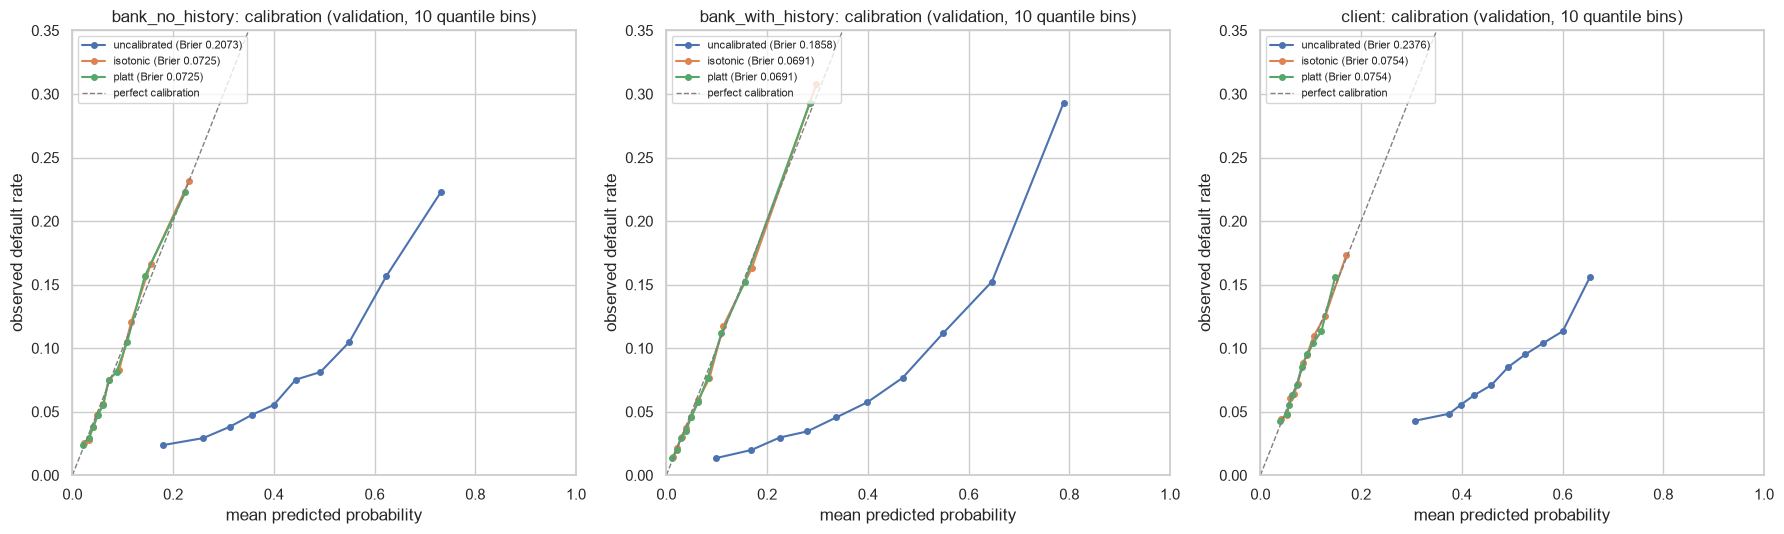

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (name, m) in zip(axes, models.items()):
    for label, p in m["probs"].items():
        frac, mean_p = calibration_curve(y_val, p, n_bins=10, strategy="quantile")
        ax.plot(mean_p, frac, marker="o", ms=4, lw=1.5, label=f"{label} (Brier {e8['lists'][name]['brier'][label]:.4f})")
    lim = max(0.35, float(max(m["probs"]["isotonic"].max(), m["probs"]["platt"].max())))
    ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="perfect calibration")
    ax.set_xlim(0, 1); ax.set_ylim(0, 0.35)
    ax.set_title(f"{name}: calibration (validation, 10 quantile bins)")
    ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed default rate")
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
save(fig, "13_calibration_curves.png")
plt.show()

## 2. E14 — Risk classes (calibrated probability)

Thresholds fixed in advance: low < 5% · medium 5-12% · high ≥ 12%. Bank: accept / accept with conditions / refuse
(recommendation only). Client: favorable / to strengthen / fragile.

In [5]:
e14, class_tables = s5.run_e14(val, models)
for name, table in class_tables.items():
    print(f"=== {name} (calibration: {e14['lists'][name]['method']})")
    display(table.assign(share=lambda t: (t["share"] * 100).round(2),
                         default_rate=lambda t: (t["default_rate"] * 100).round(2),
                         mean_predicted=lambda t: (t["mean_predicted"] * 100).round(2))
                 .rename(columns={"share": "share (%)", "default_rate": "actual default rate (%)",
                                  "mean_predicted": "mean calibrated p (%)"}))
    print("Checks:", e14["lists"][name]["checks"])

=== bank_no_history (calibration: platt)


,label,clients,defaults,mean calibrated p (%),share (%),actual default rate (%)
class,,,,,,
low,accept,14121,459,3.33,33.83,3.25
medium,accept with conditions,18873,1393,7.76,45.22,7.38
high,refuse,8741,1631,18.11,20.94,18.66


Checks: {'max_class_share': 0.45221037498502453, 'class_over_80_percent': False, 'empty_classes': [], 'default_rates_increase': True, 'limitation': False}
=== client (calibration: platt)


,label,clients,defaults,mean calibrated p (%),share (%),actual default rate (%)
class,,,,,,
low,favorable,4757,214,4.06,11.40,4.50
medium,to strengthen,30523,2355,7.80,73.14,7.72
high,fragile,6455,914,14.03,15.47,14.16


Checks: {'max_class_share': 0.7313525817659039, 'class_over_80_percent': False, 'empty_classes': [], 'default_rates_increase': True, 'limitation': False}


Figure saved: reports/figures/14_risk_classes.png


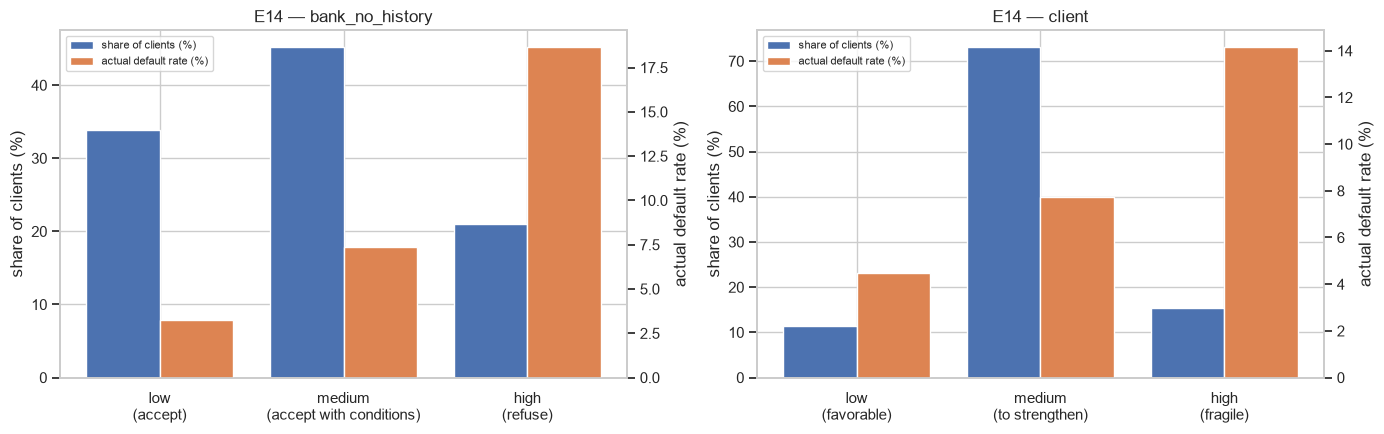

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (name, table) in zip(axes, class_tables.items()):
    x = np.arange(len(table))
    ax.bar(x - 0.2, table["share"] * 100, width=0.4, label="share of clients (%)", color="#4C72B0")
    ax2 = ax.twinx()
    ax2.bar(x + 0.2, table["default_rate"] * 100, width=0.4, label="actual default rate (%)", color="#DD8452")
    ax.set_xticks(x, [f"{c}\n({table.loc[c, 'label']})" for c in table.index])
    ax.set_ylabel("share of clients (%)"); ax2.set_ylabel("actual default rate (%)"); ax2.grid(False)
    ax.set_title(f"E14 — {name}")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
fig.tight_layout()
save(fig, "14_risk_classes.png")
plt.show()

## 3. E4 — Region features (not used in Noria whatever the result)

In [7]:
e4, _ = s5.run_e4(train, val, models)
print(f"without REGION_FEATURES (52 features): {e4['without_region']['roc_auc']:.4f} [{e4['without_region']['ci_low']:.4f}, {e4['without_region']['ci_high']:.4f}]")
print(f"with REGION_FEATURES ({e4['n_features_with_region']} features, {e4['n_trees_with_region']} trees): "
      f"{e4['with_region']['roc_auc']:.4f} [{e4['with_region']['ci_low']:.4f}, {e4['with_region']['ci_high']:.4f}]")
print(f"with - without: {ci(e4['with_minus_without'])}")
print("Decision:", e4["decision"])

without REGION_FEATURES (52 features): 0.7091 [0.6990, 0.7177]
with REGION_FEATURES (55 features, 463 trees): 0.7138 [0.7042, 0.7229]
with - without: +0.0047 [+0.0021, +0.0073]
Decision: REGION_FEATURES not used in Noria


## 4. E5 — Clients without a credit-bureau record (validation)

`bureau.csv` is only read for its `SK_ID_CURR` list (never a feature). The final measurement on the test set is left for the final-evaluation session.

In [8]:
e5, no_bureau = s5.run_e5(val, models)
print(f"Validation clients absent from bureau.csv: {e5['subgroup_rows']:,} ({e5['subgroup_share']:.1%}) · "
      f"default rate {e5['subgroup_default_rate']:.2%} vs {e5['others_default_rate']:.2%} for the others")
e5_table = pd.DataFrame([
    {"model": name, **{f"{part} AUC [95% CI]": f"{r[part]['roc_auc']:.4f} [{r[part]['ci_low']:.4f}, {r[part]['ci_high']:.4f}]"
                       for part in ["all", "no_bureau_record", "with_bureau_record"]}}
    for name, r in e5["models"].items()
])
e5_table

Validation clients absent from bureau.csv: 5,861 (14.0%) · default rate 10.82% vs 7.94% for the others


,model,all AUC [95% CI],no_bureau_record AUC [95% CI],with_bureau_record AUC [95% CI]
0,bank_no_history,"0.7091 [0.6990, 0.7177]","0.7174 [0.6958, 0.7396]","0.7051 [0.6955, 0.7151]"
1,bank_with_history,"0.7663 [0.7580, 0.7741]","0.7555 [0.7347, 0.7741]","0.7663 [0.7570, 0.7752]"
2,client,"0.6207 [0.6107, 0.6307]","0.6240 [0.6001, 0.6474]","0.6178 [0.6074, 0.6288]"


## 5. E6 — Target population (AUC by employment type and by age)

Groups with fewer than 50 defaults or non-defaults are flagged **too small to conclude**.

In [9]:
e6, e6_tables = s5.run_e6(val, models)
for name, t in e6_tables.items():
    print(f"=== {name} (overall validation AUC {e6['lists'][name]['overall_auc']:.4f})")
    for kind in ["income_type", "age"]:
        display(t[kind].round(4))

=== bank_no_history (overall validation AUC 0.7091)


,rows,defaults,default_rate,too_small,roc_auc,ci_low,ci_high
group,,,,,,,
Commercial associate,9642,739,0.0766,False,0.6944,0.6740,0.7127
Other,6,2,0.3333,True,0.5000,0.0000,1.0000
Pensioner,7755,417,0.0538,False,0.6571,0.6293,0.6843
State servant,3058,174,0.0569,False,0.7044,0.6654,0.7464
Working,21274,2151,0.1011,False,0.7066,0.6950,0.7182


,rows,defaults,default_rate,too_small,roc_auc,ci_low,ci_high
group,,,,,,,
20-25,1370,180,0.1314,False,0.6995,0.6593,0.7377
25-35,9783,1093,0.1117,False,0.7043,0.6875,0.7208
35-45,11505,992,0.0862,False,0.6970,0.6798,0.7144
45-55,9558,723,0.0756,False,0.6925,0.6715,0.7136
55-70,9519,495,0.0520,False,0.6704,0.6452,0.6966
20-35 (aggregate),11153,1273,0.1141,False,0.7047,0.6905,0.7195


=== client (overall validation AUC 0.6207)


,rows,defaults,default_rate,too_small,roc_auc,ci_low,ci_high
group,,,,,,,
Commercial associate,9642,739,0.0766,False,0.5891,0.5687,0.6093
Other,6,2,0.3333,True,0.1250,0.0000,0.6000
Pensioner,7755,417,0.0538,False,0.5550,0.5278,0.5819
State servant,3058,174,0.0569,False,0.5687,0.5265,0.6133
Working,21274,2151,0.1011,False,0.6069,0.5937,0.6193


,rows,defaults,default_rate,too_small,roc_auc,ci_low,ci_high
group,,,,,,,
20-25,1370,180,0.1314,False,0.5910,0.5467,0.6319
25-35,9783,1093,0.1117,False,0.5911,0.5741,0.6091
35-45,11505,992,0.0862,False,0.5894,0.5695,0.6077
45-55,9558,723,0.0756,False,0.5865,0.5646,0.6073
55-70,9519,495,0.0520,False,0.5779,0.5493,0.6025
20-35 (aggregate),11153,1273,0.1141,False,0.5921,0.5752,0.6091


Figure saved: reports/figures/15_e6_auc_by_group.png


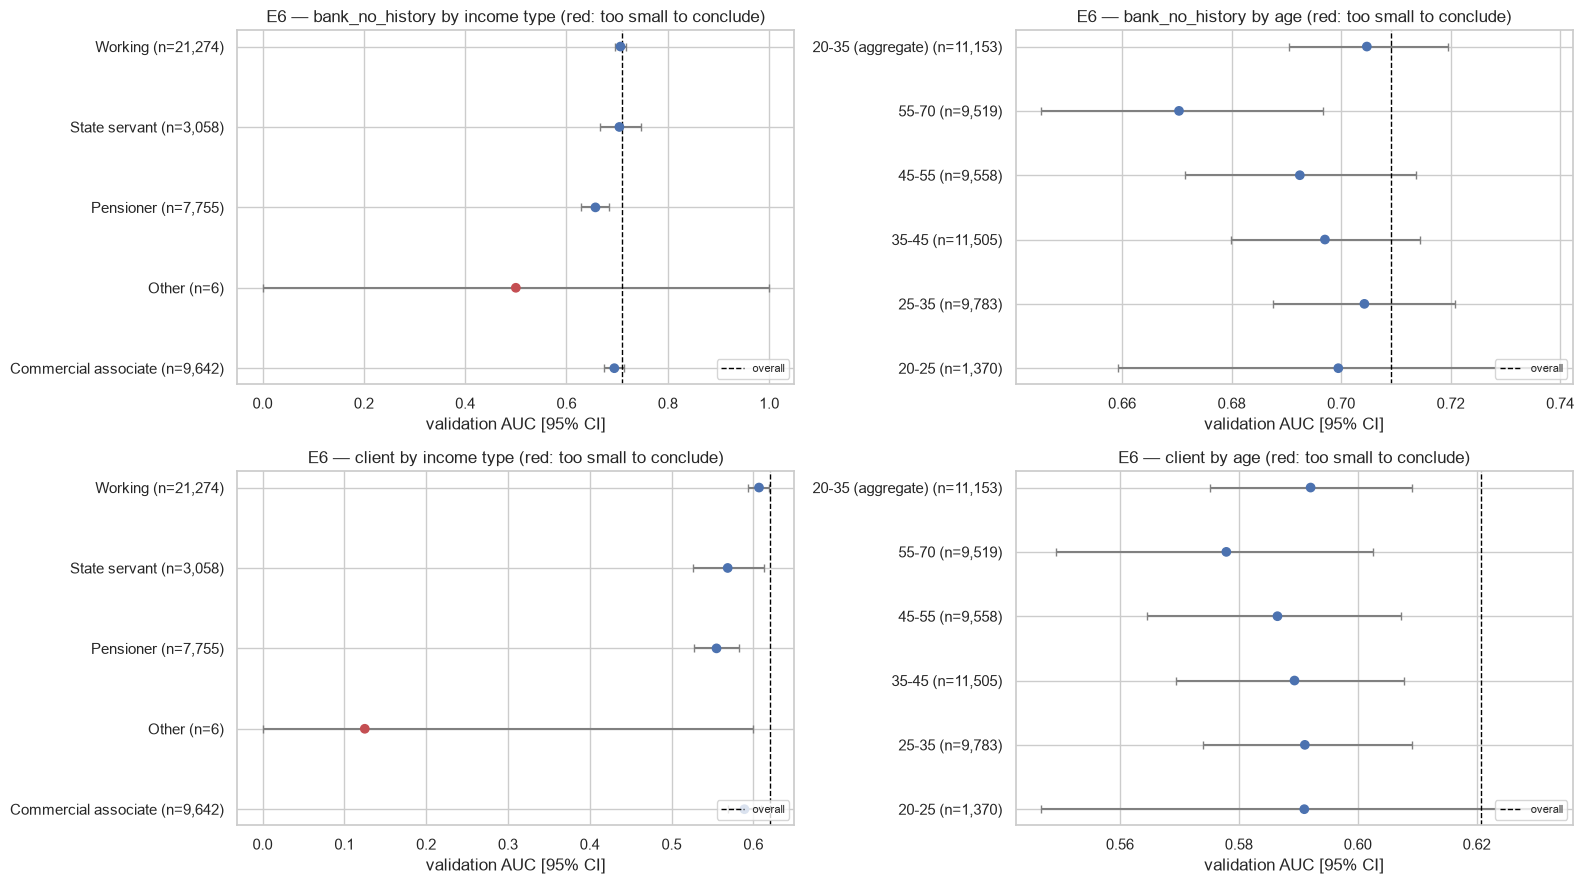

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for row, name in enumerate(["bank_no_history", "client"]):
    for col, kind in enumerate(["income_type", "age"]):
        t = e6_tables[name][kind].dropna(subset=["roc_auc"])
        ax = axes[row, col]
        colors = ["#C44E52" if s else "#4C72B0" for s in t["too_small"]]
        ax.errorbar(t["roc_auc"], range(len(t)), xerr=[t["roc_auc"] - t["ci_low"], t["ci_high"] - t["roc_auc"]],
                    fmt="none", ecolor="grey", capsize=3)
        ax.scatter(t["roc_auc"], range(len(t)), c=colors, zorder=3)
        ax.set_yticks(range(len(t)), [f"{g} (n={n:,})" for g, n in zip(t.index, t["rows"])])
        ax.axvline(e6["lists"][name]["overall_auc"], color="black", ls="--", lw=1, label="overall")
        ax.set_title(f"E6 — {name} by {kind.replace('_', ' ')} (red: too small to conclude)")
        ax.set_xlabel("validation AUC [95% CI]"); ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
save(fig, "15_e6_auc_by_group.png")
plt.show()

## 6. E9 (bonus) — Fairness audit (Fairlearn)

Acceptance = class "low". False negative = defaulter placed in "low" (accepted); false positive = non-defaulter not in "low".

In [11]:
e9, e9_frames = s5.run_e9(val, models)
for name, frames in e9_frames.items():
    for attr, frame in frames.items():
        print(f"=== {name} by {attr}")
        display(frame.astype(float).round(4))
        print("max gap between groups:", {k: round(v, 4) for k, v in e9["lists"][name][attr]["max_gap_between_groups"].items()})

=== bank_no_history by CODE_GENDER


,acceptance_rate,false_negative_rate,false_positive_rate,rows,defaults
sensitive_feature_0,,,,,
F,0.3673,0.1506,0.6160,27455.0,1965.0
M,0.2827,0.1074,0.6964,14280.0,1518.0


max gap between groups: {'acceptance_rate': 0.0846, 'false_negative_rate': 0.0433, 'false_positive_rate': 0.0804}
=== bank_no_history by age_group


,acceptance_rate,false_negative_rate,false_positive_rate,rows,defaults
sensitive_feature_0,,,,,
20-25,0.1000,0.0111,0.8866,1370.0,180.0
25-35,0.1898,0.0604,0.7939,9783.0,1093.0
35-45,0.3128,0.1190,0.6689,11505.0,992.0
45-55,0.3672,0.1715,0.6168,9558.0,723.0
55-70,0.5272,0.3010,0.4604,9519.0,495.0


max gap between groups: {'acceptance_rate': 0.4272, 'false_negative_rate': 0.2899, 'false_positive_rate': 0.4261}
=== client by CODE_GENDER


,acceptance_rate,false_negative_rate,false_positive_rate,rows,defaults
sensitive_feature_0,,,,,
F,0.1269,0.0738,0.8690,27455.0,1965.0
M,0.0891,0.0455,0.9057,14280.0,1518.0


max gap between groups: {'acceptance_rate': 0.0378, 'false_negative_rate': 0.0283, 'false_positive_rate': 0.0366}
=== client by age_group


,acceptance_rate,false_negative_rate,false_positive_rate,rows,defaults
sensitive_feature_0,,,,,
20-25,0.0000,0.0000,1.0000,1370.0,180.0
25-35,0.0042,0.0000,0.9953,9783.0,1093.0
35-45,0.0620,0.0413,0.9361,11505.0,992.0
45-55,0.1470,0.1065,0.8497,9558.0,723.0
55-70,0.2729,0.1939,0.7227,9519.0,495.0


max gap between groups: {'acceptance_rate': 0.2729, 'false_negative_rate': 0.1939, 'false_positive_rate': 0.2773}


## 7. SHAP explanations

TreeExplainer on the final models' raw output (log-odds, before calibration). Global importance on a random sample of
2,000 validation clients; two individual files per model (the median client of class "low" and of class "high").

In [12]:
sample = val.sample(2000, random_state=config.RANDOM_STATE)
shap_results = {}
for name in ["bank_no_history", "client"]:
    m = models[name]
    sv, base, X, margin = explain.explain(m["pipeline"], sample, m["features"])
    shap_results[name] = (sv, base, X)
    print(f"{name}: base value {base:.4f} (log-odds) · additivity max error |base + sum(SHAP) - raw output| = "
          f"{explain.additivity_error(sv, base, margin):.2e}")
    display(explain.global_importance(sv).head(10).round(4).rename("mean |SHAP|").to_frame())

bank_no_history: base value -0.2942 (log-odds) · additivity max error |base + sum(SHAP) - raw output| = 6.27e-15


,mean |SHAP|
CREDIT_TERM,0.3019
GOODS_CREDIT_RATIO,0.1318
EMPLOYMENT_YEARS,0.1033
AGE_YEARS,0.0966
ID_PUBLISH_YEARS,0.0892
NAME_EDUCATION_TYPE_Higher education,0.0814
OWN_CAR_AGE,0.0561
EMPLOYMENT_AGE_RATIO,0.0505
FLAG_WORK_PHONE,0.0498
ANNUITY_INCOME_RATIO,0.0478


client: base value -0.0832 (log-odds) · additivity max error |base + sum(SHAP) - raw output| = 2.22e-15


,mean |SHAP|
EMPLOYMENT_YEARS,0.1883
AGE_YEARS,0.1767
NAME_INCOME_TYPE_Working,0.1106
CREDIT_INCOME_RATIO,0.0722
NAME_FAMILY_STATUS_Married,0.0641
NAME_INCOME_TYPE_State servant,0.0196
NAME_INCOME_TYPE_Commercial associate,0.0100
NAME_FAMILY_STATUS_Single / not married,0.0071
NAME_FAMILY_STATUS_Widow,0.0052
IS_PENSIONER,0.0050


Figure saved: reports/figures/16_shap_summary_bank_no_history.png


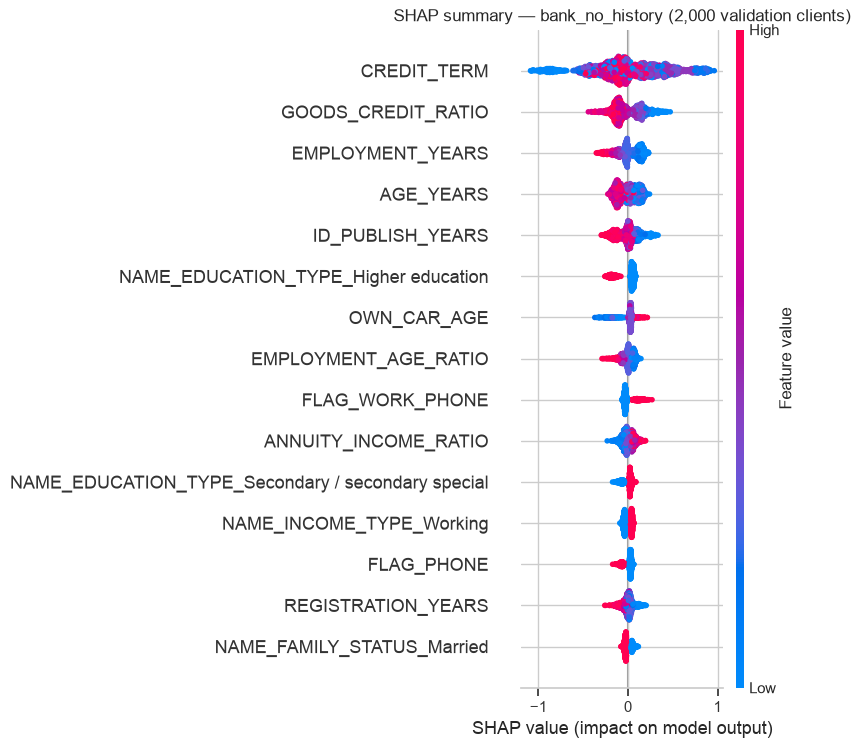

Figure saved: reports/figures/17_shap_summary_client.png


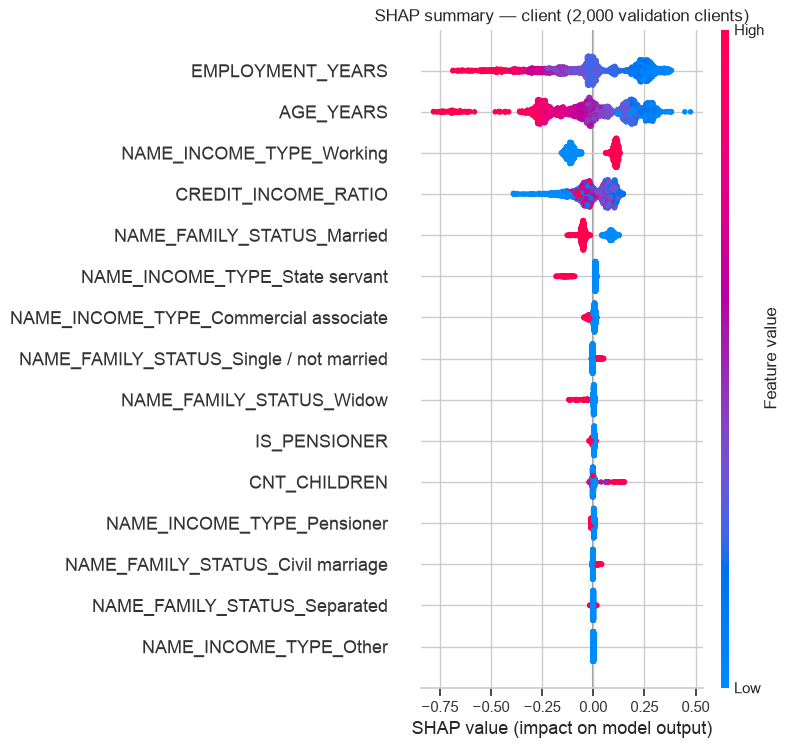

In [13]:
for name, fname in [("bank_no_history", "16_shap_summary_bank_no_history.png"), ("client", "17_shap_summary_client.png")]:
    sv, base, X = shap_results[name]
    plt.figure()
    shap.summary_plot(sv.to_numpy(), X.to_numpy(), feature_names=list(sv.columns), max_display=15, show=False)
    plt.title(f"SHAP summary — {name} (2,000 validation clients)")
    save(plt.gcf(), fname)
    plt.show()

In [14]:
examples = {}
for name in ["bank_no_history", "client"]:
    m = models[name]
    classes = risk.assign_class(m["p_cal"])
    labels = risk.BANK_RECOMMENDATION if name == "bank_no_history" else risk.CLIENT_CATEGORY
    for cls in ["low", "high"]:
        idx = np.where(classes == cls)[0]
        pick = idx[np.argsort(m["p_cal"][idx])[len(idx) // 2]]           # median client of the class
        row = val.iloc[[pick]]
        sv, base, X, margin = explain.explain(m["pipeline"], row, m["features"])
        top = explain.top_factors(sv, X, sv.index[0], k=5)
        examples[(name, cls)] = top
        print(f"=== {name} · class '{cls}' ({labels[cls]}) · SK_ID_CURR {int(row[config.ID_COL].iloc[0])} · "
              f"calibrated p = {m['p_cal'][pick]:.2%} · actual TARGET = {int(row[config.TARGET].iloc[0])} · "
              f"additivity error {explain.additivity_error(sv, base, margin):.1e}")
        display(top.round(4))

=== bank_no_history · class 'low' (accept) · SK_ID_CURR 270893 · calibrated p = 3.43% · actual TARGET = 0 · additivity error 6.7e-16


,feature,value (preprocessed),SHAP (log-odds),effect
0,CREDIT_TERM,23.4646,-0.2713,lowers the risk
1,AGE_YEARS,56.3395,-0.1859,lowers the risk
2,GOODS_CREDIT_RATIO,1.0000,-0.1155,lowers the risk
3,FLAG_PHONE,1.0000,-0.1019,lowers the risk
4,REGISTRATION_YEARS,27.2717,-0.0987,lowers the risk


=== bank_no_history · class 'high' (refuse) · SK_ID_CURR 176144 · calibrated p = 16.59% · actual TARGET = 0 · additivity error 2.1e-15


,feature,value (preprocessed),SHAP (log-odds),effect
0,CREDIT_TERM,20.4551,0.7042,raises the risk
1,EMPLOYMENT_YEARS,0.7584,0.1778,raises the risk
2,GOODS_CREDIT_RATIO,0.8256,0.1412,raises the risk
3,AGE_YEARS,31.5756,0.1361,raises the risk
4,OCCUPATION_TYPE_Core staff,1.0000,-0.1000,lowers the risk


=== client · class 'low' (favorable) · SK_ID_CURR 325854 · calibrated p = 4.20% · actual TARGET = 0 · additivity error 3.3e-16


,feature,value (preprocessed),SHAP (log-odds),effect
0,AGE_YEARS,65.4976,-0.4333,lowers the risk
1,CREDIT_INCOME_RATIO,1.0000,-0.1735,lowers the risk
2,NAME_FAMILY_STATUS_Married,0.0000,0.0852,raises the risk
3,NAME_INCOME_TYPE_Working,0.0000,-0.0697,lowers the risk
4,NAME_FAMILY_STATUS_Widow,1.0000,-0.0423,lowers the risk


=== client · class 'high' (fragile) · SK_ID_CURR 181584 · calibrated p = 13.78% · actual TARGET = 0 · additivity error 7.8e-16


,feature,value (preprocessed),SHAP (log-odds),effect
0,EMPLOYMENT_YEARS,0.5996,0.2931,raises the risk
1,AGE_YEARS,35.6605,0.1828,raises the risk
2,NAME_INCOME_TYPE_Working,1.0000,0.1150,raises the risk
3,CREDIT_INCOME_RATIO,3.9231,0.0738,raises the risk
4,NAME_FAMILY_STATUS_Married,1.0000,-0.0474,lowers the risk


## Findings

Validation set (41,735 clients, 8.35% defaults); final session 4 models (52 / 65 / 7 features, tuned). The test set stayed locked.

1. **E8 — Calibration.** The raw scores are far too high, because of `class_weight="balanced"`: their mean is 0.435 / 0.396 / 0.480, against an observed default rate of 0.0835. Brier scores, uncalibrated → isotonic → Platt:
   - bank without history: 0.20732 → 0.07253 → **0.07251**;
   - bank with history: 0.18584 → 0.06906 → **0.06906** (0.069057);
   - client: 0.23762 → 0.07538 → **0.07538** (0.075381).

   **Platt is selected for the three models** (best Brier, rule applied as written), but its margin over isotonic is negligible: at most 0.00002, with paired CIs that include 0 (e.g. [−0.000006, +0.000048]). Calibration itself is **adopted** under the adoption rule: the Brier improvements over the uncalibrated models are +0.1348 [+0.1324, +0.1370], +0.1168 [+0.1145, +0.1191] and +0.1622 [+0.1599, +0.1643]. After calibration, the mean predicted probability (0.0843 / 0.0843 / 0.0834) matches the observed rate.
2. **E14 — Risk classes (calibrated, thresholds 5% / 12%).**
   - Bank without history: low/accept **33.83%** of clients (actual default rate 3.25%), medium/accept with conditions **45.22%** (7.38%), high/refuse **20.94%** (18.66%).
   - Client: favorable **11.40%** (4.50%), to strengthen **73.14%** (7.72%), fragile **15.47%** (14.16%).

   For both models the default rates increase from low to high and no class exceeds 80% (the client's largest class: 73.14%). No E14 limitation is triggered.
3. **E4 — Region features**: with them the bank model without history reaches 0.7138 [0.7042, 0.7229] vs 0.7091 [0.6990, 0.7177] without, a gain of **+0.0047** [+0.0021, +0.0073] (55 features, 463 trees). As pre-registered, they are **not used in Noria**; the gain is reported as a lead for a real bank.
4. **E5 — Clients without a credit-bureau record** (validation): 5,861 clients (14.0%), whose default rate is higher (10.82% vs 7.94%).
   - Bank without history: **0.7174** [0.6958, 0.7396] on them vs 0.7091 overall.
   - Bank with history: 0.7555 [0.7347, 0.7741] vs 0.7663.
   - Client: 0.6240 [0.6001, 0.6474] vs 0.6207.

   The model without history performs at least as well on real no-history profiles, and the advantage of the history model shrinks there (0.7555 − 0.7174 ≈ 0.038, vs 0.057 overall). The final test measurement is left for the final-evaluation session.
5. **E6 — Target population (validation AUC [95% CI])**.
   - Bank without history: `Commercial associate` 0.6944 [0.6740, 0.7127], `Working` 0.7066, `State servant` 0.7044, `Pensioner` 0.6571. By age: from 0.6995 (20-25) to 0.6704 (55-70); **20-35: 0.7047** [0.6905, 0.7195].
   - Client: `Commercial associate` **0.5891** [0.5687, 0.6093], `Working` 0.6069, `State servant` 0.5687, `Pensioner` 0.5550. Within each age group 0.578-0.592; **20-35: 0.5921** [0.5752, 0.6091].
   - `Other` (6 rows) is too small to conclude. All other groups have at least 50 defaults and 50 non-defaults.
6. **E9 — Fairness (acceptance = class "low").**
   - Bank without history by sex: acceptance F **36.73%** vs M **28.27%** (gap 8.46 points); false negative rate F 15.06% vs M 10.74%; false positive rate F 61.60% vs M 69.64%.
   - Bank without history by age: acceptance rises from **10.00% (20-25)** to **52.72% (55-70)**, and the false positive rate falls from 88.66% to 46.04%.
   - Client: acceptance F 12.69% vs M 8.91%; by age **0.00% (20-25)**, **0.42% (25-35)**, 6.20%, 14.70%, 27.29% (55-70).

   Gender is not a feature, yet the gaps follow the observed default rates in the validation set (F 7.16% vs M 10.63%; 13.14% for 20-25 vs 5.20% for 55-70) through correlated variables.
7. **SHAP.** Additivity holds: |base + sum of SHAP − raw output| ≤ 6.3e-15 on the 2,000-client sample and on the individual files.
   - **Bank without history, global importance (mean |SHAP|)**: `CREDIT_TERM` 0.302, `GOODS_CREDIT_RATIO` 0.132, `EMPLOYMENT_YEARS` 0.103, `AGE_YEARS` 0.097, `ID_PUBLISH_YEARS` 0.089, higher education 0.081.
   - **Client, global importance**: `EMPLOYMENT_YEARS` 0.188, `AGE_YEARS` 0.177, `NAME_INCOME_TYPE_Working` 0.111, `CREDIT_INCOME_RATIO` 0.072, married 0.064.
   - **Individual files (median client of a class)**:
     - bank, accept (p = 3.43%): `CREDIT_TERM`, age 56 and `GOODS_CREDIT_RATIO` = 1 lower the risk;
     - bank, refuse (p = 16.59%): `CREDIT_TERM` (+0.70 log-odds) and an employment length of 0.76 years raise it;
     - client, favorable (p = 4.20%): age 65 and a credit/income ratio of 1.0 lower it;
     - client, fragile (p = 13.78%): employment length 0.6 years, age 36 and "Working" raise it.